# CompBench Agent Evaluation

Runs the MMEdit agent on CompBench mixed-instruction annotations. Shared JSONL/Hugging Face image loading, reference preparation, agent execution, and raw debug capture live in `evaluation/common.py`.

Install with `uv sync --extra models --extra benchmark`. By default this notebook reads `~/Datasets/MMEdit/compbench/annotations.jsonl`; override it with `MMEDIT_COMPBENCH_ANNOTATIONS` or edit the path below. Configure `MMEDIT_API_KEY` or `GOOGLE_API_KEY`. Start with a few annotation indices, inspect outputs and trajectories, then expand. HF image references use original split row indices.

In [1]:
import os
import sys
from pathlib import Path

PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Open this notebook from within the MMEdit repository.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
if str(PROJECT_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / 'src'))

from IPython.display import display
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from evaluation.common import HFImageLoader, annotate_sample, load_sample, read_jsonl, run_benchmark, select_reference_prompts

BENCHMARK = 'compbench'
RANDOM_SEED = 42
ANNOTATION_FILE = Path(os.environ.get('MMEDIT_COMPBENCH_ANNOTATIONS', '~/Datasets/MMEdit/compbench/annotations.jsonl')).expanduser().resolve()
OUTPUT_DIR = PROJECT_ROOT / 'outputs/evaluation' / BENCHMARK
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
if not ANNOTATION_FILE.is_file():
    raise FileNotFoundError(f'CompBench JSONL not found: {ANNOTATION_FILE}. Set MMEDIT_COMPBENCH_ANNOTATIONS.')
records = list(read_jsonl(ANNOTATION_FILE))
if not records:
    raise ValueError(f'No annotations found in {ANNOTATION_FILE}')
image_loader = HFImageLoader()
print(f'{len(records)} CompBench annotations loaded from {ANNOTATION_FILE}')
print('Fields:', sorted(records[0]))

2608 CompBench annotations loaded from /Users/nghialt3670/Datasets/MMEdit/compbench/annotations.jsonl
Fields: ['benchmark', 'linguistic_stats', 'metadata', 'mixed_instruction', 'original_instruction', 'parser_instruction', 'references', 'sample_id', 'source_ref', 'split', 'target_ref', 'validation']


CompBench overview: 2608 annotations
add                total= 981  index=   0  add:001ca3cb/0/00003.png  add a gray fish on <v1> with its head downward
remove             total=1331  index= 981  remove:001ca3cb/0/00002.png  remove <v1>
replace            total= 152  index=2312  replace:001ca3cb/0/00010.png  replace <v1> with a black camera long lens
multi_object_add   total=  72  index=2464  multi_object_add:02b72b8d_00002.png  add a yellow fish in front of <v1> and a white fish above <v2> to the upper left of the yellow fish
multi_object_remove total=  72  index=2537  multi_object_remove:02b72b8d_00014.png  remove <v1> and <v2>


/Users/nghialt3670/Projects/MMEdit/mmedit-framework/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


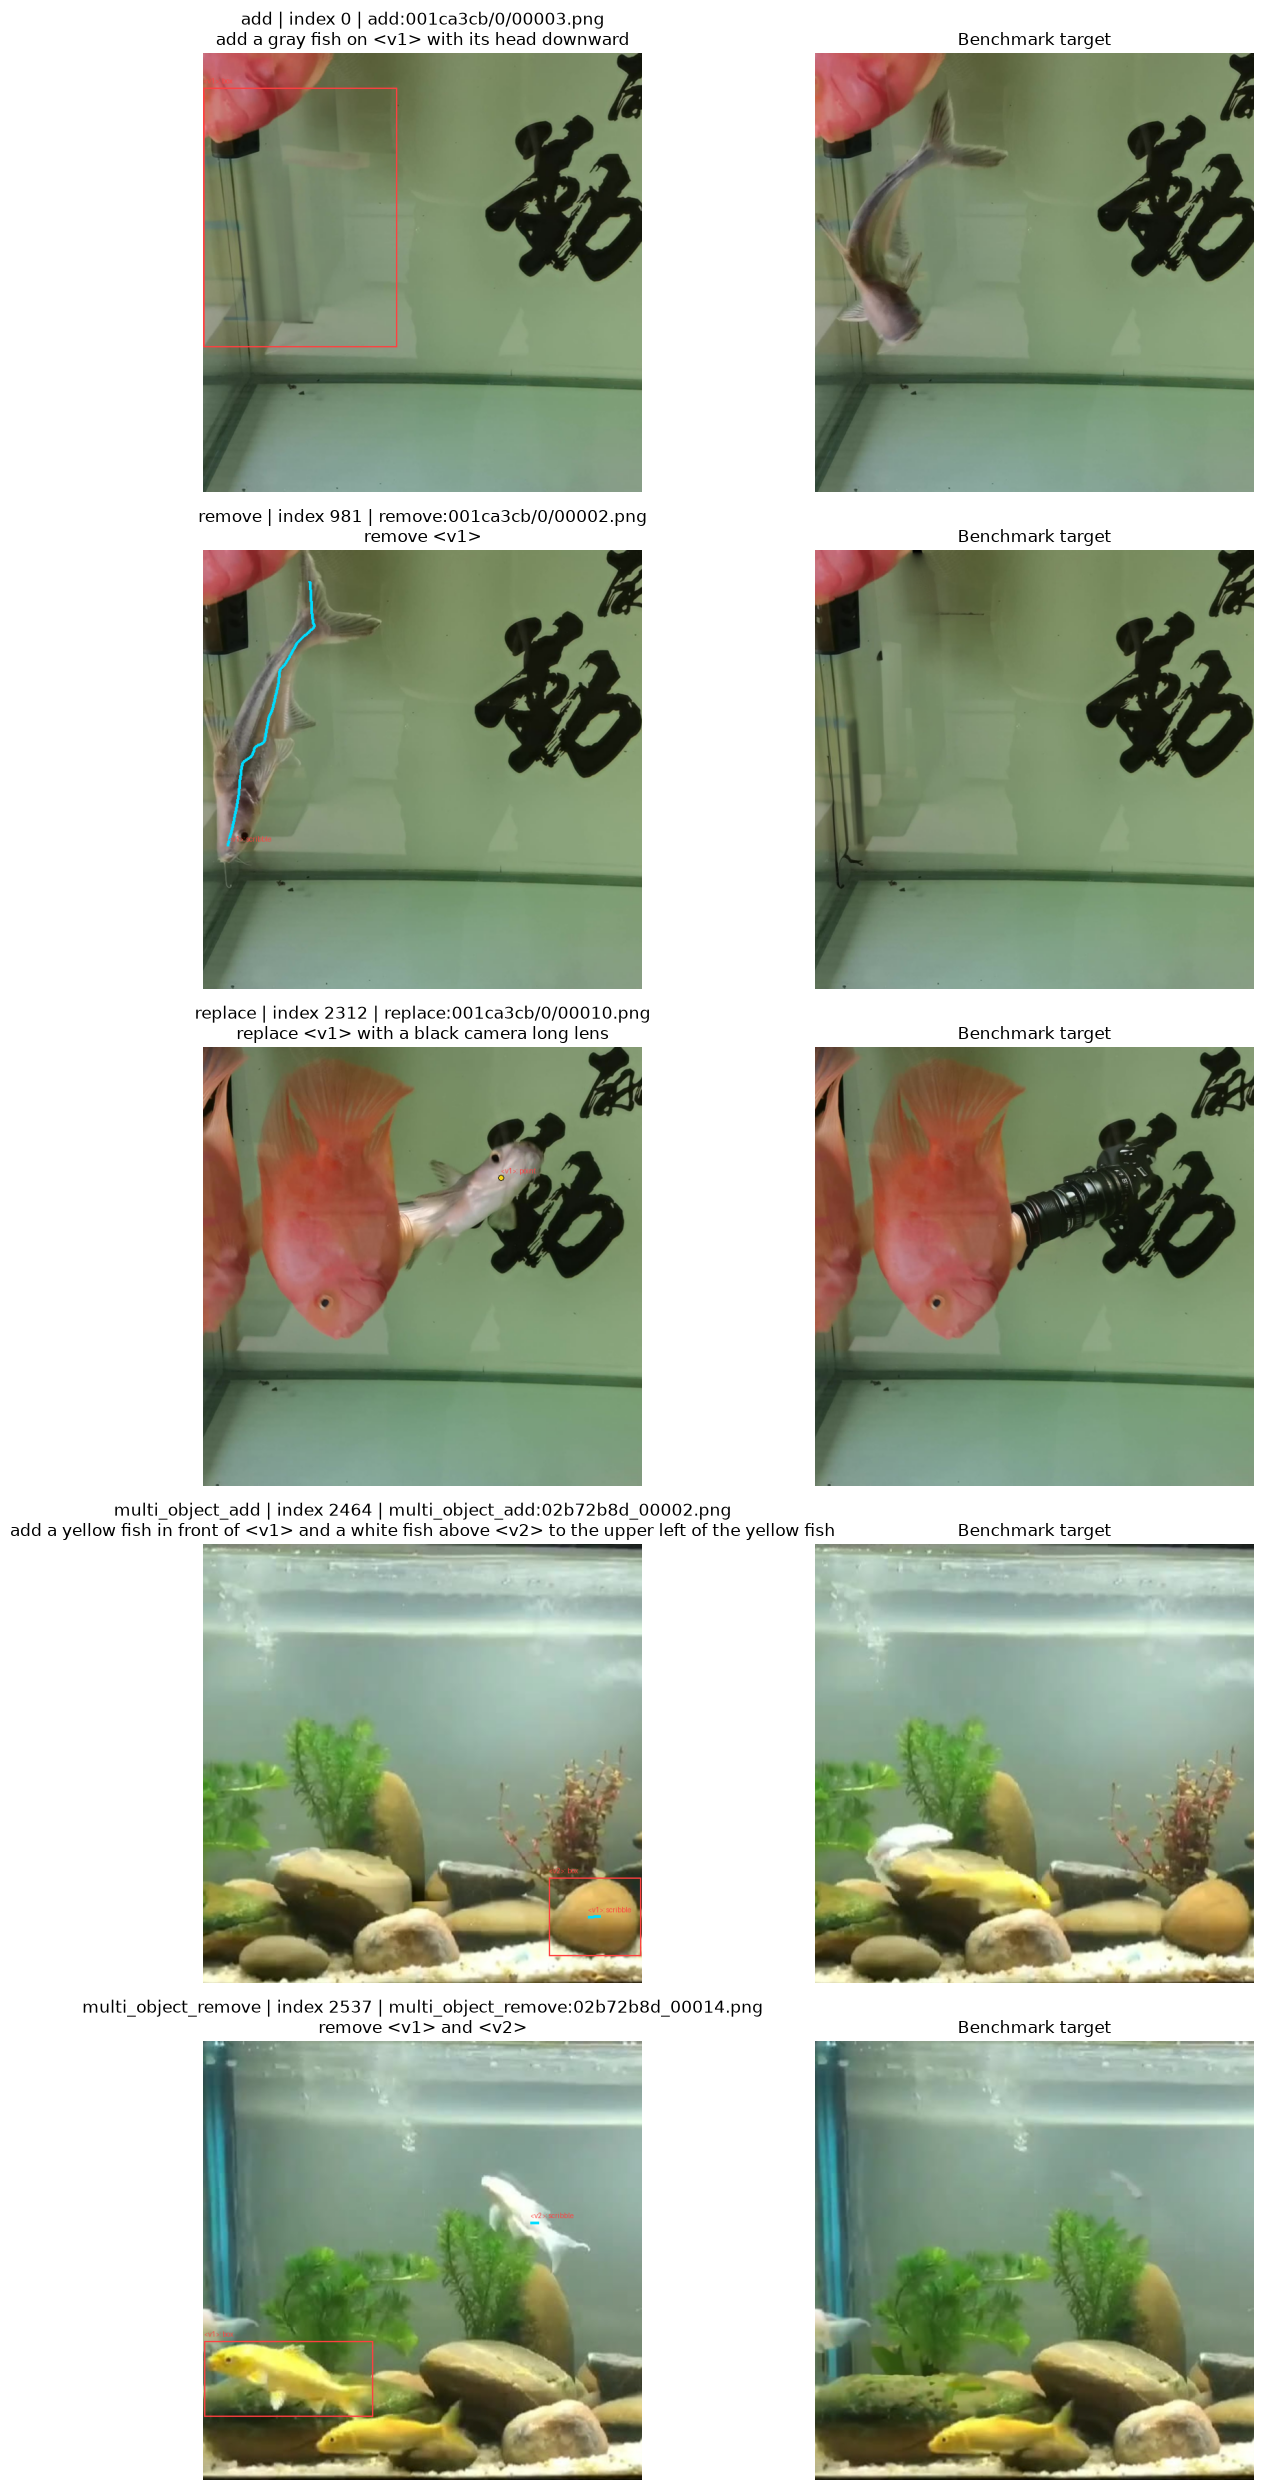

Run indices: [0, 981, 2312, 2464, 2537]
Debug outputs: /Users/nghialt3670/Projects/MMEdit/mmedit-framework/outputs/evaluation/compbench/representative_debug


In [2]:
from collections import Counter

TASK_TYPES = ("add", "remove", "replace", "multi_object_add", "multi_object_remove")
task_counts = Counter((record.get("metadata") or {}).get("task") for record in records)
representative_indices = {}

for annotation_index, record in enumerate(records):
    task_type = (record.get("metadata") or {}).get("task")
    if task_type not in TASK_TYPES or task_type in representative_indices:
        continue
    reference_count = len(record.get("references", []))
    if reference_count == 0:
        continue
    if task_type in {"multi_object_add", "multi_object_remove"} and reference_count < 2:
        continue
    representative_indices[task_type] = annotation_index

missing_tasks = set(TASK_TYPES) - representative_indices.keys()
if missing_tasks:
    raise ValueError(f"No representative CompBench samples found for: {sorted(missing_tasks)}")

SAMPLE_INDICES = sorted(representative_indices.values())
DEBUG_OUTPUT_DIR = OUTPUT_DIR / "representative_debug"
print(f"CompBench overview: {len(records)} annotations")
for task_type in TASK_TYPES:
    annotation_index = representative_indices[task_type]
    record = records[annotation_index]
    print(
        f"{task_type:18} total={task_counts[task_type]:4}  index={annotation_index:4}  "
        f"{record['sample_id']}  {record['mixed_instruction']}"
    )

fig, axes = plt.subplots(len(SAMPLE_INDICES), 2, figsize=(14, 5 * len(SAMPLE_INDICES)))
for row, annotation_index in enumerate(SAMPLE_INDICES):
    record = records[annotation_index]
    sample = load_sample(record, benchmark=BENCHMARK, image_loader=image_loader)
    select_reference_prompts(sample, seed=RANDOM_SEED)
    task_type = (record.get("metadata") or {}).get("task")

    axes[row, 0].imshow(annotate_sample(sample))
    axes[row, 0].set_title(
        f"{task_type} | index {annotation_index} | {record['sample_id']}\n"
        f"{sample['instruction']}"
    )
    axes[row, 0].axis("off")
    if sample["target_image"] is None:
        axes[row, 1].text(0.5, 0.5, "No target image", ha="center", va="center")
    else:
        axes[row, 1].imshow(sample["target_image"])
    axes[row, 1].set_title("Benchmark target")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()
print("Run indices:", SAMPLE_INDICES)
print("Debug outputs:", DEBUG_OUTPUT_DIR)

In [3]:
from smolagents import OpenAIModel
from tools import image_editing_tools

MODEL_ID = os.environ.get('MMEDIT_MODEL_ID', 'gemini-2.5-flash')
API_BASE = os.environ.get('MMEDIT_OPENAI_BASE_URL', 'https://generativelanguage.googleapis.com/v1beta/openai/')
API_KEY = os.environ.get('MMEDIT_API_KEY') or os.environ.get('GOOGLE_API_KEY')
if not API_KEY: raise EnvironmentError('Set MMEDIT_API_KEY or GOOGLE_API_KEY.')
llm = OpenAIModel(model_id=MODEL_ID, api_base=API_BASE, api_key=API_KEY, temperature=0)
tools = image_editing_tools()
print('CompBench agent ready:', MODEL_ID)

CompBench agent ready: gemini-2.5-flash


╭──────────────────────────────────────────────────── New run ────────────────────────────────────────────────────╮
│                                                                                                                 │
│ {"type": "user_message", "text": "add a gray fish on <v1> with its head downward", "objects": ["image_0",       │
│ "box_0"]}                                                                                                       │
│                                                                                                                 │
╰─ OpenAIModel - gemini-2.5-flash ────────────────────────────────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  image_1 = generate_object(image=image_0, mask=None, box=box_0, prompt='a gray fish with its head downward',      
  phrase='a gray fish with its head downward')                                                                     
  send_message(text='Here is the image with the gray fish added.', objects=[image_1])                              
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

/Users/nghialt3670/Projects/MMEdit/mmedit-framework/.venv/lib/python3.13/site-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)
Loading pipeline components...:  71%|███████▏  | 5/7 [00:00<00:00, 28.90it/s]An error occurred while trying to fetch /Users/nghialt3670/.cache/huggingface/hub/models--masterful--gligen-1-4-inpainting-text-box/snapshots/d6d957f8d27c40889c0d570a616571a5645c8be3/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /Users/nghialt3670/.cache/huggingface/hub/models--masterful--gligen-1-4-inpainting-text-box/snapshots/d6d957f8d27c40889c0d570a616571a5645c8be3/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
An error occurred while trying to fetch /Users/nghialt3670/.cache/huggingface/hub/models--masterful--gligen-1-4-inpa

Final answer: {'text': 'Here is the image with the gray fish added.', 'objects': [<PIL.Image.Image image mode=RGB 
size=640x640 at 0x4388EF4D0>]}

[Step 1: Duration 43.44 seconds| Input tokens: 2,223 | Output tokens: 121]

add:001ca3cb/0/00003.png completed 77.76 seconds


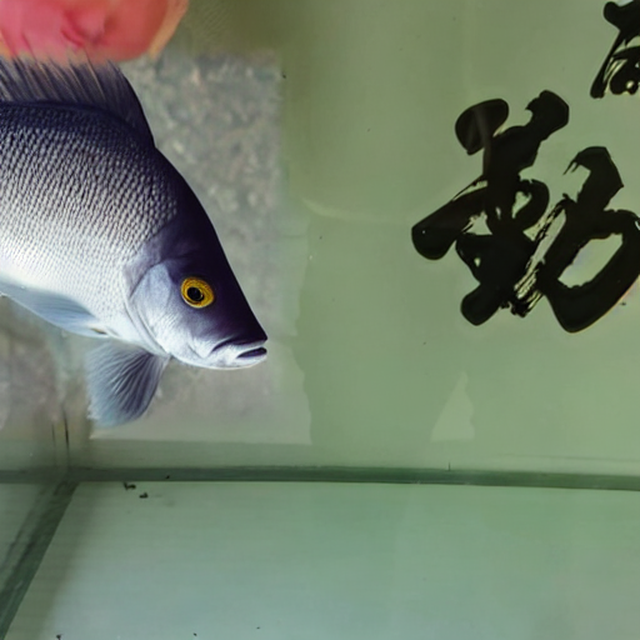

╭──────────────────────────────────────────────────── New run ────────────────────────────────────────────────────╮
│                                                                                                                 │
│ {"type": "user_message", "text": "remove <v1>", "objects": ["image_0", "scribble_0"]}                           │
│                                                                                                                 │
╰─ OpenAIModel - gemini-2.5-flash ────────────────────────────────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  mask_0 = segment_object(image=image_0, scribble=scribble_0)                                                      
  image_1 = remove_object(image=image_0, mask=mask_0)                                                              
  send_message(text="I have removed the object.", objects=[image_1])                                               
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Loading weights: 100%|██████████| 1468/1468 [00:00<00:00, 9477.81it/s]
[transformers] `memory_attention_rope_theta` is deprecated and will be removed in v5.0. Use `rope_parameters['rope_theta']` instead.
[transformers] You are using a model of type `sam3_video` to instantiate a model of type `sam3_tracker`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.
Loading weights: 100%|██████████| 196/196 [00:00<00:00, 10444.99it/s].75it/s]
The config attributes {'decay': 0.9999, 'inv_gamma': 1.0, 'min_decay': 0.0, 'optimization_step': 37000, 'power': 0.6666666666666666, 'update_after_step': 0, 'use_ema_warmup': False} were passed to UNet2DConditionModel, but are not expected and will be ignored. Please verify your config.json configuration file.
Loading 

Final answer: {'text': 'I have removed the object.', 'objects': [<PIL.Image.Image image mode=RGB size=640x640 at 
0x3C37AB050>]}

[Step 1: Duration 34.67 seconds| Input tokens: 2,215 | Output tokens: 114]

remove:001ca3cb/0/00002.png completed 121.81 seconds


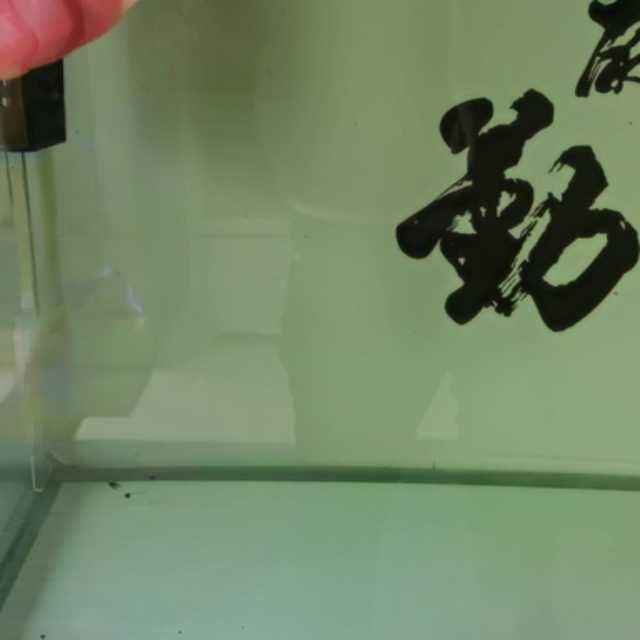

╭──────────────────────────────────────────────────── New run ────────────────────────────────────────────────────╮
│                                                                                                                 │
│ {"type": "user_message", "text": "replace <v1> with a black camera long lens", "objects": ["image_0",           │
│ "point_0"]}                                                                                                     │
│                                                                                                                 │
╰─ OpenAIModel - gemini-2.5-flash ────────────────────────────────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  mask_0 = segment_object(image=image_0, point=point_0)                                                            
  image_1 = generate_object(image=image_0, mask=mask_0, prompt="a black camera long lens")                         
  send_message(text="Here is the image with the fish replaced by a black camera long lens.", objects=[image_1])    
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Loading pipeline components...:  71%|███████▏  | 5/7 [00:00<00:00, 27.70it/s]An error occurred while trying to fetch /Users/nghialt3670/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /Users/nghialt3670/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
An error occurred while trying to fetch /Users/nghialt3670/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /Users/nghialt3670/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet.
Defaulting to unsafe seria

Final answer: {'text': 'Here is the image with the fish replaced by a black camera long lens.', 'objects': 
[<PIL.Image.Image image mode=RGB size=640x640 at 0x4401D5D50>]}

[Step 1: Duration 39.15 seconds| Input tokens: 2,224 | Output tokens: 145]

replace:001ca3cb/0/00010.png completed 154.64 seconds


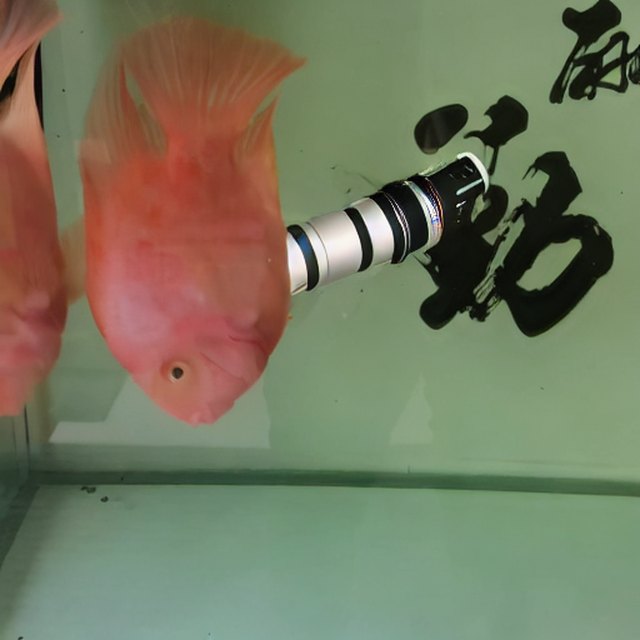

╭──────────────────────────────────────────────────── New run ────────────────────────────────────────────────────╮
│                                                                                                                 │
│ {"type": "user_message", "text": "add a yellow fish in front of <v1> and a white fish above <v2> to the upper   │
│ left of the yellow fish", "objects": ["image_0", "scribble_0", "box_1"]}                                        │
│                                                                                                                 │
╰─ OpenAIModel - gemini-2.5-flash ────────────────────────────────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  mask_0 = segment_object(image=image_0, scribble=scribble_0)                                                      
  image_1 = generate_object(image=image_0, mask=mask_0, prompt='a yellow fish in front of the rock')               
  mask_1 = segment_object(image=image_1, box=box_1)                                                                
  image_2 = generate_object(image=image_1, mask=mask_1, prompt='a white fish above the rock and to the upper left  
  of the yellow fish')                                                                                             
  send_message(text='Here are the fish you requested.', objects=[image_2])                                         
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

100%|██████████| 50/50 [00:26<00:00,  1.92it/s]


Final answer: {'text': 'Here are the fish you requested.', 'objects': [<PIL.Image.Image image mode=RGB size=640x640
at 0x3EA2960D0>]}

[Step 1: Duration 58.36 seconds| Input tokens: 2,264 | Output tokens: 219]

multi_object_add:02b72b8d_00002.png completed 97.4 seconds


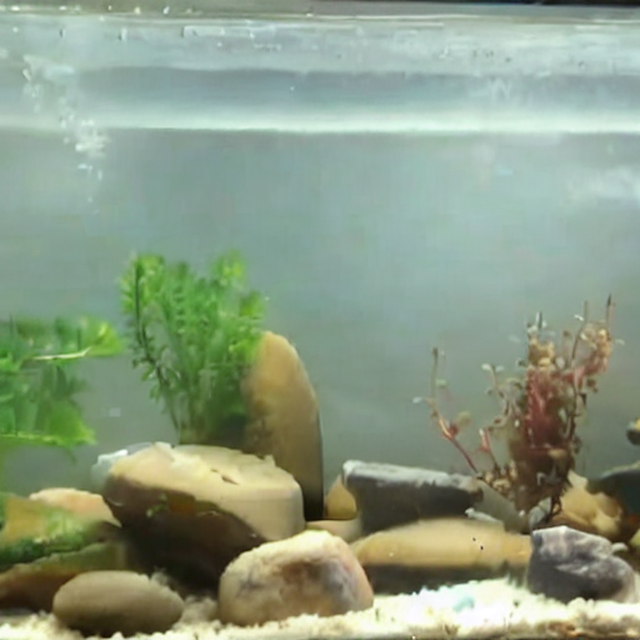

╭──────────────────────────────────────────────────── New run ────────────────────────────────────────────────────╮
│                                                                                                                 │
│ {"type": "user_message", "text": "remove <v1> and <v2>", "objects": ["image_0", "box_0", "scribble_1"]}         │
│                                                                                                                 │
╰─ OpenAIModel - gemini-2.5-flash ────────────────────────────────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  mask_0 = segment_object(image=image_0, box=box_0)                                                                
  image_1 = remove_object(image=image_0, mask=mask_0)                                                              
  mask_1 = segment_object(image=image_1, scribble=scribble_1)                                                      
  image_2 = remove_object(image=image_1, mask=mask_1)                                                              
  send_message(text="I have removed both objects.", objects=[image_2])                                             
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

100%|██████████| 8/8 [00:00<00:00,  8.52it/s]


Final answer: {'text': 'I have removed both objects.', 'objects': [<PIL.Image.Image image mode=RGB size=640x640 at 
0x4401DF6D0>]}

[Step 1: Duration 13.13 seconds| Input tokens: 2,251 | Output tokens: 168]

multi_object_remove:02b72b8d_00014.png completed 14.0 seconds


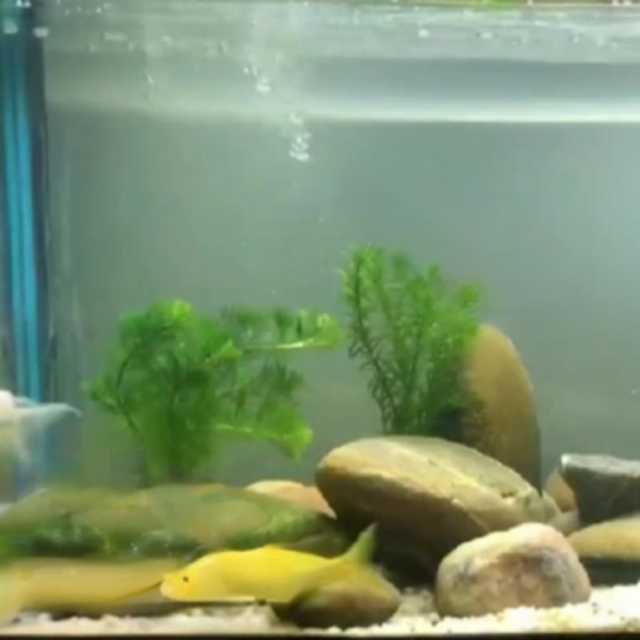

Saved run summary: /Users/nghialt3670/Projects/MMEdit/mmedit-framework/outputs/evaluation/compbench/representative_debug/results/results.jsonl
Debug output directory: /Users/nghialt3670/Projects/MMEdit/mmedit-framework/outputs/evaluation/compbench/representative_debug
Per-sample raw steps and trajectory files are included in the results entries.


In [4]:
# Annotation positions are distinct from the original HF dataset row indices in hf:// references.
# Runs one deterministic representative per CompBench task type.
benchmark_results = run_benchmark(
    records,
    SAMPLE_INDICES,
    benchmark=BENCHMARK,
    output_dir=DEBUG_OUTPUT_DIR,
    image_loader=image_loader,
    model=llm,
    tools=tools,
    seed=RANDOM_SEED,
    display_fn=display,
)
print('Debug output directory:', DEBUG_OUTPUT_DIR)
print('Per-sample raw steps and trajectory files are included in the results entries.')

In [ ]:
completed = [r for r in benchmark_results if r['status'] == 'completed']
failed = [r for r in benchmark_results if r['status'] == 'failed']
print(f'CompBench samples: {len(benchmark_results)} | completed: {len(completed)} | failed: {len(failed)}')
if benchmark_results: print(f"Mean runtime: {sum(r['elapsed_seconds'] for r in benchmark_results)/len(benchmark_results):.2f}s")
print('Image-quality scoring is separate; compare saved outputs with the available benchmark targets.')

CompBench samples: 5 | completed: 5 | failed: 0
Mean runtime: 93.12s
Image-quality scoring is separate; compare saved outputs with the available benchmark targets.


: 